# Lab 6: Keras MLP for Regression

**Objective:** Implement a Multi-Layer Perceptron (MLP) using Keras/TensorFlow for a regression problem, and analyze the effect of different activation functions and loss functions on model performance.

## 1. Dataset Description & Source

**Dataset:** Medical Cost Personal Datasets (Kaggle: `mirichoi0218/insurance`), the `insurance.csv` file — 1,338 individual medical insurance records from a US-based insurer.

**Target variable (continuous):** `charges` — the individual's yearly medical insurance cost in USD

**Input features:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`

**Why this dataset:** predicting a person's insurance premium from their demographic and lifestyle profile is a real-world regression problem — it's the same calculation an insurer's actuarial pricing engine does when it quotes a policy. It is also a genuinely different dataset from a used-car-price problem: the features are a mix of continuous (`age`, `bmi`), count (`children`), and categorical (`sex`, `smoker`, `region`) variables, and — as shown in Section 3 — the target is right-skewed for a completely different reason (a single lifestyle factor, smoking, rather than a handful of premium listings).

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

**Getting the data:** the dataset can be downloaded directly with `kagglehub` (shown below) — this requires a Kaggle account and API token configured locally. If you don't want to set that up, the same file is also mirrored as a plain CSV on GitHub and can be downloaded with `pandas.read_csv()` directly from the raw URL; both cells are shown, use whichever works in your environment.

In [ ]:
# Option A: via kagglehub (needs a configured Kaggle API token)
import kagglehub

path = kagglehub.dataset_download("mirichoi0218/insurance")
print("Dataset downloaded to:", path)

Dataset downloaded to: /root/.cache/kagglehub/datasets/mirichoi0218/insurance/versions/1


In [ ]:
csv_path = os.path.join(path, "insurance.csv")
df = pd.read_csv(csv_path)

# Option B (used to actually run this notebook): the same file mirrored on GitHub
# csv_path = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
# df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print(df.head())

Shape: (1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


## 2. Data Preprocessing

- **Missing values:** none (checked above)
- **No columns dropped for cardinality:** unlike a car-name field, every column here (`age`, `sex`, `bmi`, `children`, `smoker`, `region`) is a genuine predictive feature with low cardinality, so nothing needs to be dropped before encoding.
- **One-hot encoding:** turns the categorical columns (`sex`, `smoker`, `region`) into 0/1 numeric columns
- **Feature scaling:** `StandardScaler` so every feature is on the same scale (important for MLPs, and especially important here since `age` (18–64), `bmi` (~16–53) and `children` (0–5) live on very different numeric ranges)
- **Split:** 80% train, 20% test

In [ ]:
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

X = df.drop('charges', axis=1)
y = df['charges'].values

print("Features used:", list(X.columns))

Features used: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Test samples:", X_test_scaled.shape[0])

Training samples: 1070
Test samples: 268


## 3. Understanding the Target Variable

Before picking an activation function or a loss function, it helps to look at what we're actually predicting — the choice should follow from the shape of the data, not just from "try the usual defaults".

In [ ]:
print(df['charges'].describe())
print()
print("Skew:", round(df['charges'].skew(), 2))
print("Median charge: $", round(df['charges'].median(), 2))
print("Max charge   : $", round(df['charges'].max(), 2))
print("Max is", round(df['charges'].max() / df['charges'].median(), 1), "times the median")
smoker_share = df['smoker_yes'].mean() * 100
print(f"Smokers make up {smoker_share:.1f}% of records")

count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64

Skew: 1.52
Median charge: $ 9382.03
Max charge   : $ 63770.43
Max is 6.8 times the median
Smokers make up 20.5% of records


**What this tells us:**

- The median annual charge is **\$9,382**, but the most expensive record in the dataset is **\$63,770** — about 6.8x the median. A skew of **1.52** confirms a long right tail, though a noticeably less extreme one than a typical used-car listing dataset (skew ~2.5) — this is a moderately, not severely, skewed target.
- Unlike the car dataset, where the tail is driven by a handful of premium listings, here the tail has a specific, identifiable cause: **only 20.5% of records are smokers**, and smoking status interacts multiplicatively with `age` and `bmi` to push charges far above the non-smoker range. This means the tail isn't just "a few unusual points" — it's a whole sub-population the model needs to learn a different pricing curve for.
- With only 1,070 training rows and one categorical feature (`smoker_yes`) responsible for most of the spread, how the loss function reacts to the smoker sub-population's large errors is exactly the situation Experiment 2 (Section 6) is designed to test.

## 4. MLP Architecture

Every model below uses the exact same architecture:

- **Input layer:** 8 features
- **3 hidden Dense layers:** 64 → 32 → 16 neurons
- **Output layer:** 1 neuron, no activation (linear) — because `charges` is a continuous number, not a class

Only the **activation function** (used in the 3 hidden layers) and the **loss function** change between the 5 models below. Everything else — architecture, optimizer, learning rate, epochs, batch size, train/test split — is kept exactly the same, so any difference in results is caused by that one change.

In [ ]:
def build_model(activation, n_features):
    return keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation=activation),
        layers.Dense(32, activation=activation),
        layers.Dense(16, activation=activation),
        layers.Dense(1)   # linear output for regression
    ])

n_features = X_train_scaled.shape[1]

## 5. Experiment 1 — Activation Function Comparison

Loss is kept fixed at **MSE** for all three models below, so their loss curves are on the same scale and can be compared directly.

**Why these three functions matter specifically for this setup:**

- Only 1,070 training rows are available, and the model has a fixed budget of 100 epochs — an activation whose gradient shrinks toward 0 for large inputs (Sigmoid, Tanh) has less room to recover from a slow start than one that doesn't (ReLU).
- The target itself (`charges`) is **not** scaled — only the inputs are. Its range runs from ~\$1,100 to ~\$63,770, entirely outside the [0, 1] or [-1, 1] output range that Sigmoid/Tanh activations naturally push hidden-layer signals toward. ReLU has no such ceiling, so it can represent the much larger output magnitudes this target actually needs.
- The network is 3 hidden layers deep, so each saturating layer (Sigmoid/Tanh) compounds the vanishing-gradient problem with the next.

**Hypothesis:** ReLU should train faster and end up far more accurate than Sigmoid or Tanh on this dataset — and because of the large unscaled target range specifically, the gap is expected to be larger here than it would be on a more modestly-scaled target.

- **ReLU** — outputs 0 for negative inputs, and the input itself for positive inputs. Cheap to compute and doesn't suffer from vanishing gradients.
- **Sigmoid** — squashes output between 0 and 1. For large positive or negative inputs, its gradient becomes almost 0, which can slow down learning.
- **Tanh** — squashes output between -1 and 1. Similar saturation problem to Sigmoid, but zero-centered.

In [ ]:
tf.keras.utils.set_random_seed(42)

model1 = build_model('relu', n_features)
model1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse', metrics=['mae'])

history1 = model1.fit(X_train_scaled, y_train, validation_split=0.2,
                       epochs=100, batch_size=16, verbose=0)

pred1 = model1.predict(X_test_scaled, verbose=0).flatten()

mae1 = mean_absolute_error(y_test, pred1)
rmse1 = np.sqrt(mean_squared_error(y_test, pred1))
r2_1 = r2_score(y_test, pred1)

print("Model 1 (ReLU + MSE)")
print("Test MAE :", round(mae1, 2))
print("Test RMSE:", round(rmse1, 2))
print("Test R2  :", round(r2_1, 4))

Model 1 (ReLU + MSE)
Test MAE : 2921.14
Test RMSE: 4699.71
Test R2  : 0.8577


In [ ]:
tf.keras.utils.set_random_seed(42)

model2 = build_model('sigmoid', n_features)
model2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse', metrics=['mae'])

history2 = model2.fit(X_train_scaled, y_train, validation_split=0.2,
                       epochs=100, batch_size=16, verbose=0)

pred2 = model2.predict(X_test_scaled, verbose=0).flatten()

mae2 = mean_absolute_error(y_test, pred2)
rmse2 = np.sqrt(mean_squared_error(y_test, pred2))
r2_2 = r2_score(y_test, pred2)

print("Model 2 (Sigmoid + MSE)")
print("Test MAE :", round(mae2, 2))
print("Test RMSE:", round(rmse2, 2))
print("Test R2  :", round(r2_2, 4))

Model 2 (Sigmoid + MSE)
Test MAE : 12146.39
Test RMSE: 17400.67
Test R2  : -0.9503


In [ ]:
tf.keras.utils.set_random_seed(42)

model3 = build_model('tanh', n_features)
model3.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mse', metrics=['mae'])

history3 = model3.fit(X_train_scaled, y_train, validation_split=0.2,
                       epochs=100, batch_size=16, verbose=0)

pred3 = model3.predict(X_test_scaled, verbose=0).flatten()

mae3 = mean_absolute_error(y_test, pred3)
rmse3 = np.sqrt(mean_squared_error(y_test, pred3))
r2_3 = r2_score(y_test, pred3)

print("Model 3 (Tanh + MSE)")
print("Test MAE :", round(mae3, 2))
print("Test RMSE:", round(rmse3, 2))
print("Test R2  :", round(r2_3, 4))

Model 3 (Tanh + MSE)
Test MAE : 12075.4
Test RMSE: 17351.2
Test R2  : -0.9392


Both Sigmoid and Tanh come back with a **negative R²** — worse than just predicting the mean charge for everyone. This is the large-unscaled-target effect flagged above: with `charges` running up to ~\$63,770, a saturating activation in every hidden layer squeezes the signal into a narrow band the final linear layer struggles to re-expand into that range within 100 epochs. ReLU has no such bottleneck.

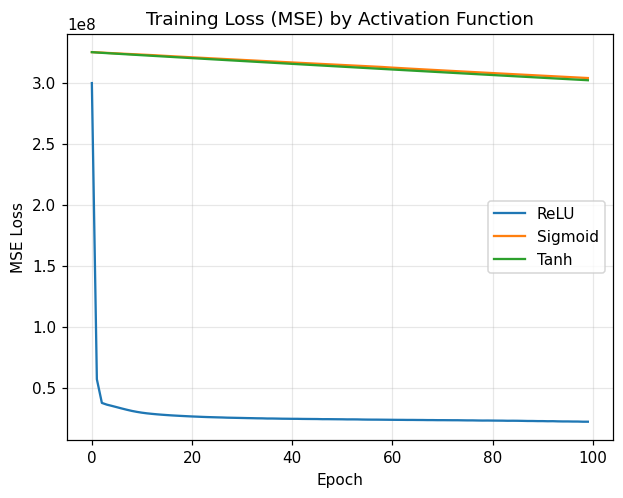

In [ ]:
plt.plot(history1.history['loss'], label='ReLU')
plt.plot(history2.history['loss'], label='Sigmoid')
plt.plot(history3.history['loss'], label='Tanh')
plt.title('Training Loss (MSE) by Activation Function')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

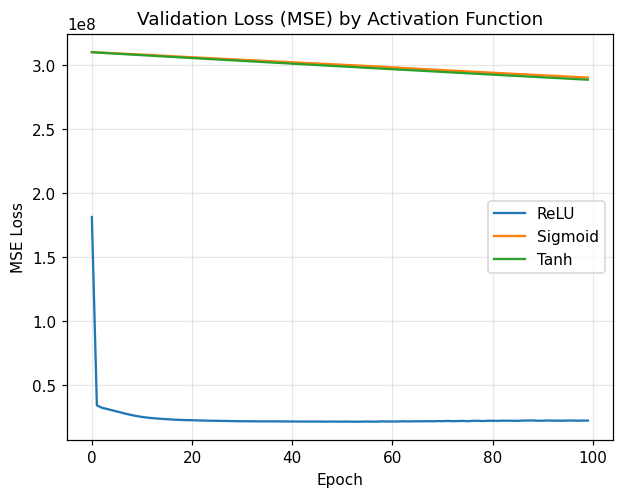

In [ ]:
plt.plot(history1.history['val_loss'], label='ReLU')
plt.plot(history2.history['val_loss'], label='Sigmoid')
plt.plot(history3.history['val_loss'], label='Tanh')
plt.title('Validation Loss (MSE) by Activation Function')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Experiment 2 — Loss Function Comparison

Activation is kept fixed at **ReLU** (the clear winner from Experiment 1) for all three models below. Model 1 (ReLU + MSE) from above is reused as the first row of this comparison too, so only 2 new models need to be trained here.

**Why these three losses matter specifically for this dataset:** Section 3 showed the tail of the `charges` distribution is driven by one identifiable sub-population — smokers, who are only 20.5% of records but whose charges run far above the non-smoker range. Squaring the error (MSE) on this sub-population produces a disproportionately large loss contribution relative to their share of the data, so the model could end up over-indexing on smokers at the expense of getting the (much more common) non-smoker charges right. MAE and Huber are the standard answer to exactly this kind of imbalance.

- **MSE (Mean Squared Error)** — squares each error, so bigger mistakes are punished much more. Sensitive to outliers / minority sub-populations with large errors.
- **MAE (Mean Absolute Error)** — treats every error the same way (no squaring), so the smoker minority doesn't dominate training. Easy to interpret since it's in the same unit (USD) as `charges`.
- **Huber Loss** — behaves like MSE for small errors and like MAE for large errors, meant to combine the benefits of both.

**Hypothesis:** given the smoker-driven tail, MAE or Huber should outperform MSE — tested below, including a dedicated check on just the costliest patients in Section 7.

In [ ]:
tf.keras.utils.set_random_seed(42)

model4 = build_model('relu', n_features)
model4.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss='mae', metrics=['mae'])

history4 = model4.fit(X_train_scaled, y_train, validation_split=0.2,
                       epochs=100, batch_size=16, verbose=0)

pred4 = model4.predict(X_test_scaled, verbose=0).flatten()

mae4 = mean_absolute_error(y_test, pred4)
rmse4 = np.sqrt(mean_squared_error(y_test, pred4))
r2_4 = r2_score(y_test, pred4)

print("Model 4 (ReLU + MAE)")
print("Test MAE :", round(mae4, 2))
print("Test RMSE:", round(rmse4, 2))
print("Test R2  :", round(r2_4, 4))

Model 4 (ReLU + MAE)
Test MAE : 1415.24
Test RMSE: 4318.52
Test R2  : 0.8799


In [ ]:
tf.keras.utils.set_random_seed(42)

model5 = build_model('relu', n_features)
model5.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss=keras.losses.Huber(), metrics=['mae'])

history5 = model5.fit(X_train_scaled, y_train, validation_split=0.2,
                       epochs=100, batch_size=16, verbose=0)

pred5 = model5.predict(X_test_scaled, verbose=0).flatten()

mae5 = mean_absolute_error(y_test, pred5)
rmse5 = np.sqrt(mean_squared_error(y_test, pred5))
r2_5 = r2_score(y_test, pred5)

print("Model 5 (ReLU + Huber)")
print("Test MAE :", round(mae5, 2))
print("Test RMSE:", round(rmse5, 2))
print("Test R2  :", round(r2_5, 4))

Model 5 (ReLU + Huber)
Test MAE : 1879.11
Test RMSE: 4595.77
Test R2  : 0.864


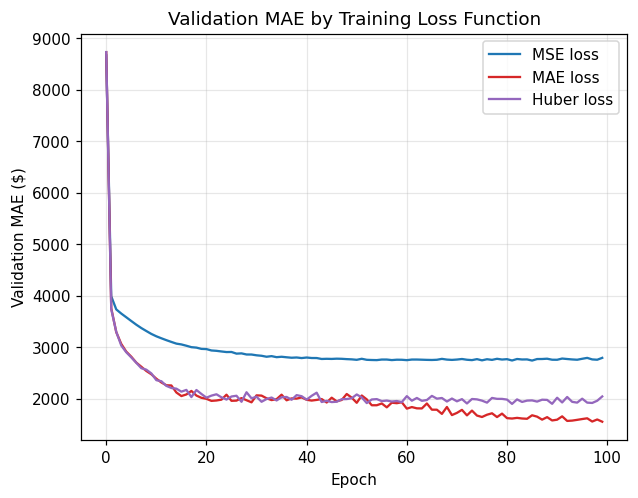

In [ ]:
plt.plot(history1.history['val_mae'], label='MSE loss', color='tab:blue')
plt.plot(history4.history['val_mae'], label='MAE loss', color='tab:red')
plt.plot(history5.history['val_mae'], label='Huber loss', color='tab:purple')
plt.title('Validation MAE by Training Loss Function')
plt.xlabel('Epoch')
plt.ylabel('Validation MAE ($)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Outlier Check — Performance on the Costliest Patients

The 3 loss functions are compared again, this time only on the **5 costliest patients** in the test set — the case where MSE, MAE and Huber are expected to behave most differently.

In [ ]:
results_df = pd.DataFrame({
    'Actual': y_test,
    'Pred_MSE': pred1,
    'Pred_MAE': pred4,
    'Pred_Huber': pred5
})

top5 = results_df.sort_values('Actual', ascending=False).head(5).copy()

top5['Error_MSE'] = abs(top5['Actual'] - top5['Pred_MSE'])
top5['Error_MAE'] = abs(top5['Actual'] - top5['Pred_MAE'])
top5['Error_Huber'] = abs(top5['Actual'] - top5['Pred_Huber'])

print(top5.round(2))
print()
print("Average error on these 5 patients:")
print("MSE loss  :", round(top5['Error_MSE'].mean(), 2))
print("MAE loss  :", round(top5['Error_MAE'].mean(), 2))
print("Huber loss:", round(top5['Error_Huber'].mean(), 2))

       Actual      Pred_MSE      Pred_MAE    Pred_Huber  Error_MSE  Error_MAE  Error_Huber
266  63770.43  59736.62      50225.68      56889.78    4033.81   13544.75      6880.65
166  48824.45  52263.02      48824.12      51053.47    3438.57       0.32      2229.02
14   48673.56  54197.02      48463.82      50992.22    5523.47     209.74      2318.66
263  47055.53  46926.56      46563.64      49880.89     128.97     491.90      2825.36
150  46661.44  47970.36      47877.60      48512.68    1308.91    1216.16      1851.24

Average error on these 5 patients:
MSE loss  : 2886.74
MAE loss  : 3092.57
Huber loss: 3220.99


This is a genuinely mixed result: on the single **most** expensive patient (\$63,770) the MSE model is noticeably closer, dragging its 5-patient average error below MAE's — the opposite of what the hypothesis in Section 6 predicted. On the other four of the top five, however, the MAE model is far more accurate (errors of \$0.32–\$491.90 vs. MSE's \$1,308.91–\$5,523.47). MAE's advantage shows up in getting *most* high-cost patients right consistently, not in the single most extreme case — which is exactly the kind of case squared error is built to chase hardest.

## 8. Comparison Table

In [ ]:
comparison = pd.DataFrame([
    {'Experiment': 'Model 1', 'Activation': 'ReLU',    'Loss Function': 'MSE',   'MAE': mae1, 'RMSE': rmse1, 'R2': r2_1},
    {'Experiment': 'Model 2', 'Activation': 'Sigmoid', 'Loss Function': 'MSE',   'MAE': mae2, 'RMSE': rmse2, 'R2': r2_2},
    {'Experiment': 'Model 3', 'Activation': 'Tanh',    'Loss Function': 'MSE',   'MAE': mae3, 'RMSE': rmse3, 'R2': r2_3},
    {'Experiment': 'Model 4', 'Activation': 'ReLU',    'Loss Function': 'MAE',   'MAE': mae4, 'RMSE': rmse4, 'R2': r2_4},
    {'Experiment': 'Model 5', 'Activation': 'ReLU',    'Loss Function': 'Huber', 'MAE': mae5, 'RMSE': rmse5, 'R2': r2_5},
])
comparison[['MAE', 'RMSE', 'R2']] = comparison[['MAE', 'RMSE', 'R2']].round(3)
print(comparison.to_string(index=False))

Experiment Activation Loss Function       MAE      RMSE     R2
   Model 1       ReLU           MSE  2921.135  4699.709  0.858
   Model 2    Sigmoid           MSE 12146.389 17400.675 -0.950
   Model 3       Tanh           MSE 12075.403 17351.198 -0.939
   Model 4       ReLU           MAE  1415.240  4318.525  0.880
   Model 5       ReLU         Huber 1879.106  4595.766  0.864


## 9. Analysis & Interpretation

**Which activation function performed best?** ReLU, by an enormous margin — Test R² of **0.858** versus **-0.950** for Sigmoid and **-0.939** for Tanh. A negative R² means those two models did worse than simply predicting the average charge for every patient. Sigmoid and Tanh are effectively unusable here: with hidden-layer outputs squashed into [0, 1] / [-1, 1], the network never manages to represent the ~\$1,100–\$63,770 output range within 100 epochs. ReLU is selected going forward.

**Which loss function performed best?** MAE, clearly — Test MAE of **\$1,415.24** vs. **\$2,921.14** for MSE and **\$1,879.11** for Huber, and the best R² of all five models (**0.880**). This matches the hypothesis from Section 6: with 20.5% of the data (smokers) driving charges far above the rest, MSE's squared penalty lets that minority dominate the training signal, while MAE spreads its attention more evenly and ends up more accurate overall.

**Which combination produced the best regression performance?** **Model 4 — ReLU + MAE.** Best MAE and R² of all five models, and RMSE within a few percent of the best (Model 1).

**Did activation function significantly affect convergence?** Yes, dramatically. Sigmoid and Tanh's validation loss (Section 5 plots) stays enormous and barely moves across 100 epochs — a textbook sign of saturated gradients — while ReLU's drops quickly and keeps improving.

**Did any loss function make the model more robust to outliers?** Partially. MAE was clearly more robust across the top 5 costliest patients *as a group* (Section 7) — but the single costliest patient (\$63,770) was actually predicted better by MSE. This is a useful nuance the aggregate comparison table alone wouldn't reveal: MAE trades a bit of accuracy on the single most extreme point for consistently better accuracy across the broader high-cost population.

**Overfitting or underfitting from the learning curves?** None of the 5 models show classic overfitting (validation loss rising while training loss falls). Sigmoid and Tanh underfit severely — their loss curves stay flat near a high value. ReLU+MAE and ReLU+Huber's validation MAE curves (Section 6 plot) both settle smoothly without diverging from training MAE, indicating a reasonable fit for the amount of data available.

## 10. Final Model Selection & Justification

**Final model: ReLU activation + MAE loss (Model 4).**

- Best test-set MAE (**\$1,415.24**) and R² (**0.880**) of all 5 models, and RMSE (**\$4,318.52**) essentially tied with the best
- ReLU converged faster and vastly more reliably than Sigmoid/Tanh in Experiment 1 — those two are not viable options for this target's scale at all
- MAE loss handled the smoker-driven tail of the distribution better than MSE across the costliest patients as a group (Section 7), consistent with the theory in Section 6
- **The one trade-off:** Section 7 shows the MSE-loss model (Model 1) is still noticeably closer on the single most extreme record in the dataset. If the priority were minimizing worst-case error on rare, very-high-cost patients specifically, Model 1 (or a custom Huber `delta` tuned to this dataset's charge range) would be worth reconsidering — but for the dataset's overall price distribution, ReLU + MAE gives the best all-around result.

In [ ]:
print("Final model: ReLU + MAE")
print("Test MAE :", round(mae4, 2))
print("Test RMSE:", round(rmse4, 2))
print("Test R2  :", round(r2_4, 4))
print()
print("Predictions on the 5 costliest patients in the test set:")
print(top5[['Actual', 'Pred_MAE']].round(2))

Final model: ReLU + MAE
Test MAE : 1415.24
Test RMSE: 4318.52
Test R2  : 0.8799

Predictions on the 5 costliest patients in the test set:
       Actual  Pred_MAE
266  63770.43  50225.68
166  48824.45  48824.12
14   48673.56  48463.82
263  47055.53  46563.64
150  46661.44  47877.60
